In [1]:
%matplotlib inline
import time
import numpy as np
from matplotlib.collections import PolyCollection
from matplotlib.figure import Figure
import active_subspaces as ac
import thermal_model as tm

SEED = 2025
T_START = time.time()

# Two-material thermal compliance: active subspace of a 512-input design problem

**Paper:** Philippe-André Luneau, "Conservative surrogate models for optimization with the active subspace method", *Engineering Optimization* 57(12):3757–3777, 2025.
Groupe Interdisciplinaire de Recherche en Éléments Finis de l'Université Laval, Département de Mathématiques et Statistique, Université Laval, Québec, Canada.

Notebook: Claude (Anthropic) for P. Constantine, 2026

The paper was read in its preprint version (arXiv:2403.15678v1, 23 March 2024); section, equation and figure numbers below refer to it. The staged PDF is that arXiv v1 preprint, not the version of record; the published article (bibliographic data above) is the one cited, and its figures were not compared with the preprint's.

## Summary

A square plate made of two conducting materials is heated by a fixed source, and the design inputs are the fractions $\theta_1,\dots,\theta_{512}$ of the better conductor in each of the 512 triangles of a finite element mesh; the quantity of interest is the thermal energy (heat compliance) $E(\theta)$, which the paper's design problem constrains by $E \le E_{\max} = 1.35$.
With 1500 exact adjoint gradients at uniformly random designs, the gradient covariance has one dominant eigenvalue, and its eigenvector is a one-signed weighting of the elements that is largest on an annulus around the centre, as in the paper's Fig. 7.
$E$ is close to a linear function of the single active variable, which is what lets the paper replace the 512-dimensional constraint by a one-dimensional surrogate.

## Active subspaces in brief

For a function $f(x)$ of $m$ normalized inputs with density $\rho$, the matrix $C = \int \nabla f\,\nabla f^\top \rho\,dx = W \Lambda W^\top$ measures how much $f$ changes, on average, along each direction: $w_i^\top C w_i = \lambda_i$ is the mean squared directional derivative along the eigenvector $w_i$. If $\lambda_n \gg \lambda_{n+1}$, $f$ varies mostly along the span of $W_1 = [w_1,\dots,w_n]$, and $f(x) \approx g(W_1^\top x)$ for some function $g$ of the $n$ active variables. $C$ is estimated from gradient samples, $\hat C = M^{-1}\sum_j \nabla f(x_j)\nabla f(x_j)^\top$, and the bootstrap gives the variability of the eigenvalues and of the subspace. See P. G. Constantine, [*Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*](https://doi.org/10.1137/1.9781611973860), SIAM, 2015.

## The model

Sec. 4.3 of the paper: steady heat conduction in $\Omega = [-1,1]^2$ with two materials, written in variational form (Eq. (8)): find $u \in H^1_0(\Omega)$ with

$$\int_\Omega \big(k_1\theta + k_2(1-\theta)\big)\,\nabla u\cdot\nabla v\,dx = \int_\Omega f\,v\,dx \quad \text{for all } v \in H^1_0(\Omega),$$

$k_1 = 2$, $k_2 = 1$, $f(x,y) = 56\,(1-|x|-|y|)^6$ (as in Delfour and Zolésio), and $u = 0$ on $\partial\Omega$. The quantity of interest is the thermal energy

$$E(\theta) = \tfrac12\int_\Omega \big(k_1\theta + k_2(1-\theta)\big)\,|\nabla u|^2\,dx = \tfrac12\int_\Omega f\,u\,dx,$$

nondimensional (the paper gives no units). The design problem, Eq. (9), minimizes the volume $V(\theta) = \int_\Omega \theta\,dx$ subject to $E(\theta) \le E_{\max} = 1.35$.

**Discretization (the author's code).** A structured mesh of $16\times16$ squares, each cut into two triangles ($D = 512$ elements), second-order Lagrange elements (1089 nodes), and $\theta$ constant on each element, $\theta_e \in [0,1]$; mixtures ($0<\theta_e<1$) stand for material distributions finer than the mesh. `thermal_model.py` is an independent numpy/scipy implementation of the discretization in the author's code (pyTOP `fem2d.py` and the CASM notebook, both MIT), with the same element numbering and quadrature; it reproduces the author's stored gradients to a relative $3\times10^{-14}$ when run with the author's boundary node list (see `DATA.md`). That list (124 nodes) leaves four of the 128 boundary nodes free; this data set uses $u=0$ at every boundary node, as the paper states. The author's 124-node variant is available as `tm.ThermalCompliance(boundary='casm')`; the comparison section below runs it at the author's inputs, and `generate_data.py --casm DIR` checks it against the author's stored files.

**Gradient.** $E = \frac12 F^\top U$ with $K(\theta)U = F$ is self-adjoint, so $\partial E/\partial\theta_e = -\frac12(k_1-k_2)\,u_e^\top K_e u_e$, with $K_e$ the unit-conductivity element stiffness: one solve gives $E$ and the whole gradient, exactly for the discrete model. Every component is negative: more of the better conductor always lowers the energy.

**Inputs.** The paper samples the design variables uniformly (Sec. 4.1; the code draws $x \sim U[-1,1]^{512}$ and sets $\theta = (x+1)/2$). The table is built from the code.

In [2]:
model = tm.ThermalCompliance()            # 16 x 16 mesh, P2, u = 0 on the whole boundary
m = model.n_elem
names = [f'theta_{e:03d}' for e in range(m)]
cent = model.element_centroids()
print(f'{m} inputs, {model.n_nodes} nodes, {model.free.size} free nodes; '
      f'k1 = {tm.K1}, k2 = {tm.K2}, E_max = {tm.E_MAX}')
print(f"{'name':<11} {'element':>7} {'centroid (x, y)':>17} {'range':>9}  distribution")
for e in list(range(4)) + [None] + list(range(m - 2, m)):
    if e is None:
        print(f"{'...':<11}")
        continue
    print(f"{names[e]:<11} {e:>7} ({cent[e, 0]:+.3f}, {cent[e, 1]:+.3f})   [0, 1]  uniform")

512 inputs, 1089 nodes, 961 free nodes; k1 = 2.0, k2 = 1.0, E_max = 1.35
name        element   centroid (x, y)     range  distribution
theta_000         0 (-0.958, -0.958)   [0, 1]  uniform
theta_001         1 (-0.917, -0.917)   [0, 1]  uniform
theta_002         2 (-0.833, -0.958)   [0, 1]  uniform
theta_003         3 (-0.792, -0.917)   [0, 1]  uniform
...        
theta_510       510 (+0.917, +0.917)   [0, 1]  uniform
theta_511       511 (+0.958, +0.958)   [0, 1]  uniform


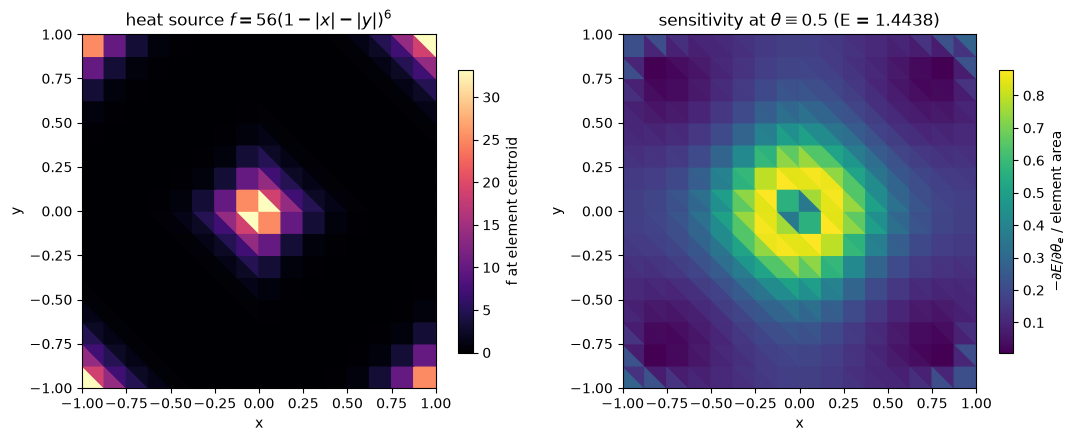

In [3]:
def field_plot(ax, values, cmap='viridis', label=None):
    """Draw one value per element on the mesh."""
    pc = PolyCollection(model.element_triangles(), array=values, cmap=cmap, edgecolors='face')
    ax.add_collection(pc)
    ax.set_xlim(-1, 1); ax.set_ylim(-1, 1); ax.set_aspect('equal')
    ax.set_xlabel('x'); ax.set_ylabel('y')
    ax.figure.colorbar(pc, ax=ax, shrink=0.8, label=label)
    return pc

E_half, g_half = model.energy_and_grad(np.full(m, 0.5))
fig = Figure(figsize=(11, 4.3)); axs = fig.subplots(1, 2)
field_plot(axs[0], tm.source(cent[:, 0], cent[:, 1]), cmap='magma', label='f at element centroid')
axs[0].set_title('heat source $f = 56(1-|x|-|y|)^6$')
field_plot(axs[1], -g_half/model.area, label=r'$-\partial E/\partial\theta_e$ / element area')
axs[1].set_title(r'sensitivity at $\theta \equiv 0.5$ (E = %.4f)' % E_half)
fig.tight_layout()
fig

The source is largest at the centre and, because the formula is used as written (without clipping at the diamond $|x|+|y|=1$), also in the four corners, where the boundary condition holds the temperature at zero. At the uniform design the energy is most sensitive on a ring around the centre, where the heat produced at the centre has to flow out.

## Load the data

`thermal_compliance.npz` holds $M = 1500$ independent uniform (Monte Carlo) samples of $\theta \in [0,1]^{512}$, stored as float32 (the model was run at exactly these values), the energy $E$ and the exact gradient $\partial E/\partial\theta$ in physical coordinates. `generate_data.py` writes it (seed 20250129, about 25 s).

In [4]:
data = np.load('thermal_compliance.npz')
X = data['theta'].astype(np.float64)        # physical inputs theta in [0, 1]
f = data['E']                                # thermal energy
G = data['dE_dtheta']                        # gradient w.r.t. theta (physical)
E_max = float(data['E_max'])
print('X', X.shape, 'f', f.shape, 'G', G.shape)
print(f'theta in [{X.min():.2e}, {X.max():.7f}]; E in [{f.min():.4f}, {f.max():.4f}]; '
      f'samples with E > E_max: {np.sum(f > E_max)} of {len(f)}; all gradient entries < 0: {bool(np.all(G < 0))}')

X (1500, 512) f (1500,) G (1500, 512)
theta in [1.98e-07, 0.9999985]; E in [1.4219, 1.5327]; samples with E > E_max: 1500 of 1500; all gradient entries < 0: True


Every random design violates the constraint: a uniform design has on average half of each material, and the paper's threshold needs more of the good conductor. This does not affect the subspace, which describes $E$ over the whole design box.

**Check.** Re-solve five samples with `thermal_model.py` and compare with the file; then compare one exact gradient with central differences.

In [5]:
rows = [0, 1, 500, 1000, 1499]
dE = [abs(model.energy(X[i]) - f[i])/f[i] for i in rows]
dG = [np.linalg.norm(model.grad(X[i]) - G[i])/np.linalg.norm(G[i]) for i in rows]
print(f'largest relative difference from the file: E {max(dE):.1e}, gradient {max(dG):.1e}')

rng = np.random.default_rng(SEED)
x0 = X[0]
v = rng.standard_normal(m)
h = 1e-4
t = np.clip(x0 + h*v, 0, 1) - x0; s = x0 - np.clip(x0 - h*v, 0, 1)
# directional difference along v, using only steps that stay inside [0, 1]
mask = np.isclose(t, h*v) & np.isclose(s, h*v)
vv = np.where(mask, v, 0.0)
fd = (model.energy(x0 + h*vv) - model.energy(x0 - h*vv))/(2*h)
print(f'directional derivative: adjoint {G[0] @ vv:.10e}, central difference {fd:.10e}, '
      f'relative difference {abs(G[0] @ vv - fd)/abs(fd):.1e}')

largest relative difference from the file: E 0.0e+00, gradient 0.0e+00
directional derivative: adjoint -1.2771078909e-02, central difference -1.2771079821e-02, relative difference 7.1e-08


## Estimate the active subspace

The gradients are exact and cheap, so the estimator is the gradient-based one (`estimator="as"`). The input space is $U[0,1]^{512}$; the library maps $\theta$ to $x = 2\theta - 1 \in [-1,1]^{512}$ and the gradients by the chain rule, so the eigenvalues are those of the gradients with respect to the code's $x$, the variables of the paper's analysis.

**Sample size.** The repository's default of $M \ge 10m = 5120$ gradients would take about 21 MB in float64, above the 10 MB limit for shipped data. $M = 1500$ ($\approx 2.9\,m$) is used instead. It is well above the heuristic $M = \alpha\,k\log m$ of Constantine (2015, Ch. 3) for $k$ eigenpairs with oversampling $\alpha \le 10$ ($10 \times 6 \times \log 512 \approx 374$ for six eigenvalues), and since $M > m$ the estimate of $C$ has full rank (the author's code used $M = m = 512$). This is enough for $\lambda_1$, $w_1$ and the dimension, but not for the tail: the smaller eigenvalues still fall as $M$ grows (see the eigenvalue results). The bootstrap has 200 replicates; the dimension is chosen by the largest eigenvalue gap (`dimension_rule="evg"`).

In [6]:
space = ac.Uniform(np.zeros(m), np.ones(m), names=names)
t0 = time.time()
sub = ac.active_subspace(space=space, X=X, grads=G, estimator='as', dimension_rule='evg',
                         nboot=200, bootstrap_vectors=1, rng=SEED)
# Sign: positive weights, as in the paper's Fig. 7 (more good conductor lowers E everywhere).
sub = ac.orient(sub, by='reference', reference=np.ones((m, 1)), columns=1)
lam = sub.eigenvalues
lo, hi = ac.bootstrap_interval(sub.bootstrap_eigenvalues[:, :6])
print(f'{time.time() - t0:.0f} s; chosen dimension n = {sub.n}')
for k in range(6):
    print(f'lambda_{k + 1} = {lam[k]:.4e}   95% bootstrap interval [{lo[k]:.4e}, {hi[k]:.4e}]')
print(f'lambda_1/lambda_2 = {lam[0]/lam[1]:.1f}, lambda_2/lambda_3 = {lam[1]/lam[2]:.3f}, '
      f'lambda_1/sum = {lam[0]/lam.sum():.4f}, lambda_512 = {lam[-1]:.2e}')
be = sub.bootstrap_eigenvalues
rlo, rhi = ac.bootstrap_interval(np.column_stack([be[:, 0]/be[:, 1], be[:, 1]/be[:, 2]]))
print(f'95% bootstrap intervals: lambda_1/lambda_2 [{rlo[0]:.1f}, {rhi[0]:.1f}], '
      f'lambda_2/lambda_3 [{rlo[1]:.3f}, {rhi[1]:.3f}]')

263 s; chosen dimension n = 1
lambda_1 = 8.7370e-04   95% bootstrap interval [8.6970e-04, 8.7650e-04]
lambda_2 = 1.5839e-06   95% bootstrap interval [1.5368e-06, 1.7313e-06]
lambda_3 = 1.4004e-06   95% bootstrap interval [1.3654e-06, 1.5562e-06]
lambda_4 = 1.3403e-06   95% bootstrap interval [1.2772e-06, 1.4184e-06]
lambda_5 = 1.1400e-06   95% bootstrap interval [1.1292e-06, 1.2531e-06]
lambda_6 = 1.1194e-06   95% bootstrap interval [1.0784e-06, 1.1872e-06]
lambda_1/lambda_2 = 551.6, lambda_2/lambda_3 = 1.131, lambda_1/sum = 0.9582, lambda_512 = 4.66e-12
95% bootstrap intervals: lambda_1/lambda_2 [504.3, 568.6], lambda_2/lambda_3 [1.033, 1.221]


## Results

### Eigenvalues

    M  mean lambda_2  mean lambda_512   (50 subsamples without replacement each)


  100     2.2216e-06         rank < m


  256     1.8023e-06         rank < m


  512     1.6697e-06         8.13e-16


 1000     1.6084e-06         3.41e-12
 1500     1.5839e-06         4.66e-12   (all samples)


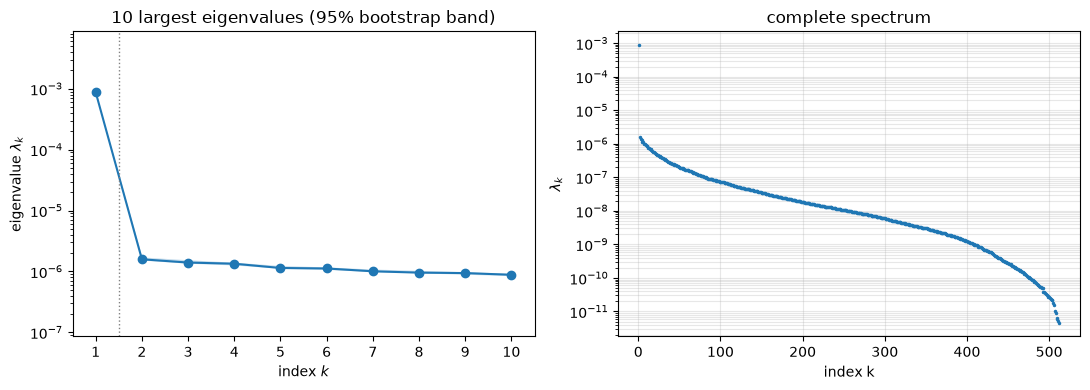

In [7]:
fig = Figure(figsize=(11, 4)); axs = fig.subplots(1, 2)
ac.plotting.plot_eigenvalues(sub, k_max=10, ax=axs[0])
axs[0].set_title('10 largest eigenvalues (95% bootstrap band)')
axs[1].semilogy(np.arange(1, m + 1), lam, '.', ms=3)
axs[1].set_xlabel('index k'); axs[1].set_ylabel(r'$\lambda_k$'); axs[1].set_title('complete spectrum')
axs[1].grid(True, which='both', alpha=0.3)
fig.tight_layout()

# Is the tail converged? Eigenvalues of subsamples of the 1500 gradients (w.r.t. x = 2 theta - 1).
Gx = G/2
rng = np.random.default_rng(SEED)
print(f"{'M':>5} {'mean lambda_2':>14} {'mean lambda_512':>16}   (50 subsamples without replacement each)")
for Ms in (100, 256, 512, 1000):
    ev = np.array([np.linalg.eigvalsh(Gx[i].T @ Gx[i]/Ms)[[-2, 0]]
                   for i in (rng.choice(len(G), Ms, replace=False) for _ in range(50))])
    tail = f'{ev[:, 1].mean():.2e}' if Ms >= m else 'rank < m'
    print(f'{Ms:>5} {ev[:, 0].mean():>14.4e} {tail:>16}')
print(f'{len(G):>5} {lam[1]:>14.4e} {lam[-1]:>16.2e}   (all samples)')
fig

The first eigenvalue, $\lambda_1 = 8.737\times10^{-4}$ (95 % bootstrap interval $[8.697, 8.765]\times10^{-4}$), is 551.6 times $\lambda_2 = 1.584\times10^{-6}$ (bootstrap interval of the ratio $[504.3, 568.6]$) and holds 95.82 % of the trace. After it the spectrum has no further gap ($\lambda_2/\lambda_3 = 1.131$, interval $[1.033, 1.221]$) and decays slowly to $\lambda_{512} = 4.66\times10^{-12}$; the gap rule picks $n = 1$, the dimension the paper chooses from its Fig. 6.

**The tail is not converged at $M = 1500$.** In subsamples of the 1500 gradients the mean $\lambda_2$ falls steadily as $M$ grows: $2.2216\times10^{-6}$ at $M = 100$, $1.8023\times10^{-6}$ at 256, $1.6697\times10^{-6}$ at 512, $1.6084\times10^{-6}$ at 1000 and $1.5839\times10^{-6}$ with all 1500. So $\lambda_2, \dots, \lambda_6$ are still biased upward, and $\lambda_1/\lambda_2 = 551.6$ is a lower estimate of the ratio for the exact $C$; $\lambda_1$, $w_1$ and $n = 1$ are not affected (see the subspace errors below).

**The paper's complete spectrum (Fig. 6b, $M = m = 512$), whose axis reaches $10^{-15}$, is a sampling effect of a square gradient matrix, not rounding.** The author's $512\times512$ gradient matrix has full rank (512), and its smallest eigenvalue, $2.72\times10^{-15}$ (comparison cell below), is $1.4\times10^{4}$ times the rounding level $\varepsilon\lambda_1 = 2.0\times10^{-19}$. With $M = m$ the smallest sample eigenvalues are pushed toward zero (mean $\lambda_{512} = 8.13\times10^{-16}$ over 50 subsamples of 512 of this data set's gradients); with $M = 1000$ and $M = 1500 \approx 2.9\,m$ they are not ($3.41\times10^{-12}$ and $4.66\times10^{-12}$).

### Subspace errors

mean bootstrap subspace distance, n = 1..4: [0.0054 0.3083 0.5231 0.3547]


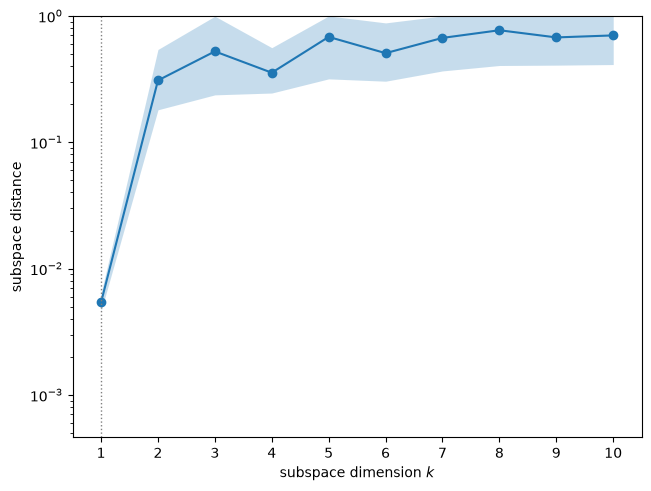

In [8]:
fig, ax = ac.plotting.plot_subspace_errors(sub, k_max=10)
dist = sub.bootstrap_distances.mean(axis=0)
print('mean bootstrap subspace distance, n = 1..4:', np.array2string(dist[:4], precision=4))
fig

The mean bootstrap distance for $n = 1$ is 0.0054, so the one-dimensional active subspace is well determined by 1500 gradients. For $n = 2, 3, 4$ the distances are 0.308, 0.523 and 0.355: $\lambda_2,\dots,\lambda_6$ lie within a factor of 1.5 of each other (1.584 to $1.119\times10^{-6}$), and their eigenvectors are not separated at this sample size; their values are also still falling with $M$ (see the eigenvalue results).

### The first eigenvector

w1: min 0.0011, max 0.1229, all positive: True; min/max = 0.009
cosine with the uniform direction (gradient of V): 0.7583; with the normalized mean gradient: 1.000000
largest component at radius 0.186; mean component for r < 0.1 (6 elements): 0.0691, 0.1 < r < 0.3: 0.1143, 0.3 < r < 0.6: 0.0591, r > 0.9: 0.0145


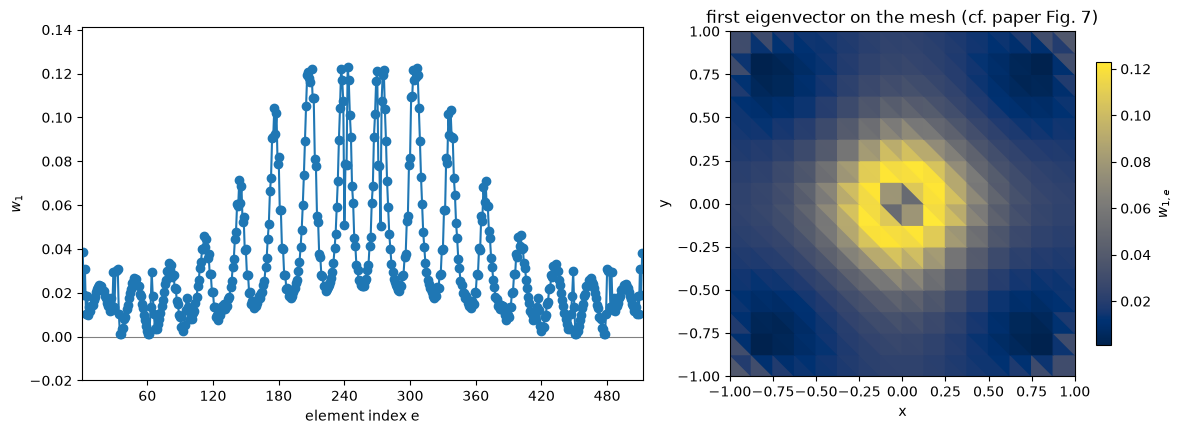

In [9]:
w1 = sub.eigenvectors[:, 0]
gbar = -G.mean(axis=0); gbar /= np.linalg.norm(gbar)
r = np.hypot(cent[:, 0], cent[:, 1])
print(f'w1: min {w1.min():.4f}, max {w1.max():.4f}, all positive: {bool(np.all(w1 > 0))}; '
      f'min/max = {w1.min()/w1.max():.3f}')
print(f'cosine with the uniform direction (gradient of V): {w1.sum()/np.sqrt(m):.4f}; '
      f'with the normalized mean gradient: {w1 @ gbar:.6f}')
print(f'largest component at radius {r[np.argmax(w1)]:.3f}; mean component for r < 0.1 ({np.sum(r < 0.1)} elements): '
      f'{w1[r < 0.1].mean():.4f}, 0.1 < r < 0.3: {w1[(r > 0.1) & (r < 0.3)].mean():.4f}, 0.3 < r < 0.6: {w1[(r > 0.3) & (r < 0.6)].mean():.4f}, '
      f'r > 0.9: {w1[r > 0.9].mean():.4f}')
fig = Figure(figsize=(12, 4.3)); axs = fig.subplots(1, 2, gridspec_kw={'width_ratios': [1.3, 1]})
ac.plotting.plot_eigenvectors(sub, indices=[0], interval='percentile', ax=[axs[0]])
axs[0].set_ylim(-0.02, 1.15*w1.max()); axs[0].set_xlabel('element index e')
field_plot(axs[1], w1, cmap='cividis', label='$w_{1,e}$')
axs[1].set_title('first eigenvector on the mesh (cf. paper Fig. 7)')
fig.tight_layout()
fig

All 512 components of $w_1$ are positive (0.0011 to 0.1229): adding the better conductor anywhere lowers the energy, and since every gradient is negative and one eigenvalue dominates, $w_1$ equals the normalized mean gradient (cosine 1.000000 to the printed digits). The weights are largest on a ring around the centre (largest component at radius 0.186; mean 0.1143 for $0.1<r<0.3$, against 0.0691 for the 6 elements nearest the centre, 0.0591 for $0.3<r<0.6$ and 0.0145 for $r>0.9$): the annular region of the paper's Fig. 7, through which the heat from the central source must flow. The cosine with the uniform direction, the gradient of the volume objective $V$ (all elements have the same area), is 0.7583, so the constraint's active direction and the objective's gradient differ, which is what gives the one-dimensional reduced design problem its content.

### Sufficient summary plot

y in [-2.235, 1.592]; E - E_max in [0.0719, 0.1827]; correlation(y, E) = -0.9941


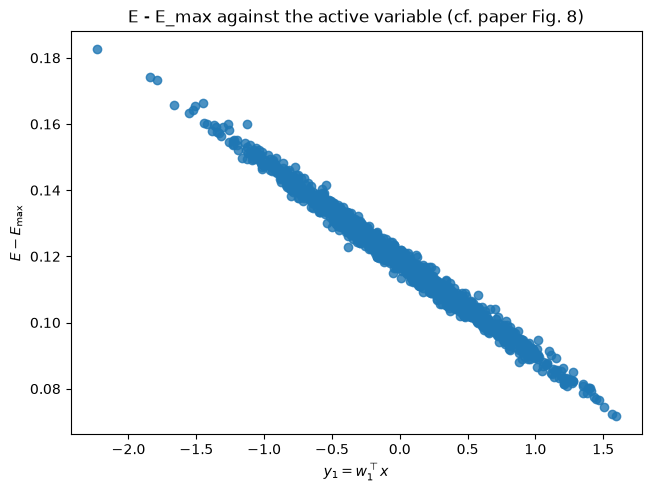

In [10]:
y = space.to_normalized(X) @ w1                 # active variable, normalized coordinates
fig, ax = ac.plotting.plot_sufficient_summary(sub, X=X, f=f - E_max, dims=1,
                                              qoi_label=r'$E - E_{\max}$')
ax.set_title('E - E_max against the active variable (cf. paper Fig. 8)')
print(f'y in [{y.min():.3f}, {y.max():.3f}]; E - E_max in [{(f - E_max).min():.4f}, {(f - E_max).max():.4f}]; '
      f'correlation(y, E) = {np.corrcoef(y, f)[0, 1]:.4f}')
fig

$E$ falls almost linearly along the active variable (correlation $-0.9941$): over $y \in [-2.235, 1.592]$, $E - E_{\max}$ goes from 0.1827 to 0.0719. The paper's Fig. 8 shows the same profile with 50 samples, $E - E_{\max}$ between about 0.1 and 0.16 (0.0943 to 0.1685 in the author's stored file, which uses the author's boundary list), and a linear fit. The scatter about the line is the variation of $E$ along the 511 inactive directions.

### Surrogate on the active variable

Polynomials in $y = w_1^\top x$, with leave-one-out $R^2$ (the paper fits a straight line to 50 samples).

degree 1: LOO R^2 = 0.98815
degree 2: LOO R^2 = 0.98831
degree 3: LOO R^2 = 0.98832


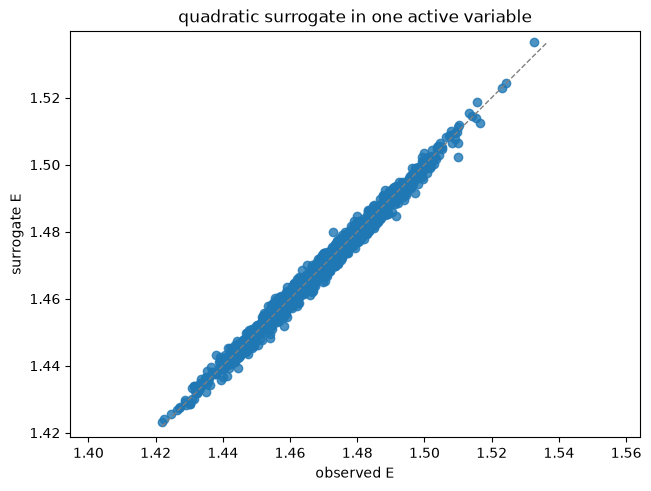

In [11]:
sur = {}
for deg in (1, 2, 3):
    sur[deg] = ac.fit_surrogate(X=X, f=f, subspace=ac.with_dimension(sub, 1), kind='poly', degree=deg)
    print(f'degree {deg}: LOO R^2 = {sur[deg].loo_r_squared:.5f}')
fig, ax = ac.plotting.plot_surrogate_fit(sur[2], X=X, f=f, qoi_label='E')
ax.set_title('quadratic surrogate in one active variable')
fig

The leave-one-out $R^2$ is 0.98815 for a straight line, 0.98831 for a quadratic and 0.98832 for a cubic: curvature adds almost nothing, which supports the paper's choice of a linear surrogate, and the remaining 1.2 % of the variance is variation along the inactive directions that no function of $y$ alone can capture.

## Comparison with the paper

The paper's numbers come from its Figs. 6–8; the author's notebook (`thermal_design_casm.ipynb` in github.com/paluneau/CASM) prints the eigenvalues behind Fig. 6 and stores the 512 gradients and the 50 profile samples. The next cell reruns that computation with `thermal_model.py`, using the author's boundary node list and the author's 512 inputs (NumPy's legacy `np.random.seed(42)` and draw order, as in that notebook), to show which differences come from the boundary condition and which from sampling.

**Rebuilding the author's 124-node variant.** `tm.ThermalCompliance(boundary='casm')` is the model with the author's Dirichlet node list (the four boundary nodes 32, 1023, 1055 and 1088 free). Its energies and gradients at this data set's 1500 inputs are `generate_data.compute(generate_data.design(), model=tm.ThermalCompliance(boundary='casm'))` (about 25 s; not shipped). With a clone of github.com/paluneau/CASM, `python generate_data.py --casm DIR` compares the variant with the author's stored `dfData.npy` and `fData.npy` and prints $\lambda_1$, $\lambda_2$ for both boundary lists; it writes no file.

In [12]:
casm = tm.ThermalCompliance(boundary='casm')
np.random.seed(42)          # the author's legacy global seed and draw order (CASM notebook, cell 7)
Xa = np.vstack(np.array([np.random.uniform(-1, 1, m) for _ in range(m)]).T)   # x in [-1, 1]
t0 = time.time()
Ga = np.array([0.5*casm.grad((x + 1)/2) for x in Xa])                         # dE/dx
Gp = np.array([0.5*model.grad((x + 1)/2) for x in Xa])
la = np.linalg.eigvalsh(Ga.T @ Ga/m)[::-1]
lp = np.linalg.eigvalsh(Gp.T @ Gp/m)[::-1]
print(f'{time.time() - t0:.0f} s for 2 x {m} gradients')
print(f"author's boundary list, author's inputs: lambda_1 = {la[0]:.6e}, lambda_2 = {la[1]:.6e}, ratio {la[0]/la[1]:.1f}")
print(f"all boundary nodes,     author's inputs: lambda_1 = {lp[0]:.6e}, lambda_2 = {lp[1]:.6e}, ratio {lp[0]/lp[1]:.1f}")
print(f"all boundary nodes,     this data set:   lambda_1 = {lam[0]:.6e}, lambda_2 = {lam[1]:.6e}, ratio {lam[0]/lam[1]:.1f}")
wa = np.linalg.eigh(Ga.T @ Ga)[1][:, -1]; wa *= np.sign(wa.sum())
print(f'change in lambda_1 from the boundary list: {100*(lp[0]/la[0] - 1):+.2f} %; '
      f'from the samples (author inputs -> this data set): {100*(lam[0]/lp[0] - 1):+.2f} %')
print(f"author's computation (M = m = {m}): rank {np.linalg.matrix_rank(Ga)}, smallest eigenvalue {la[-1]:.2e}; "
      f"rounding level eps*lambda_1 = {np.finfo(float).eps*la[0]:.1e} (ratio {la[-1]/(np.finfo(float).eps*la[0]):.1e})")
print(f"author's w1: min/max = {wa.min()/wa.max():.3f}, 1/max = {1/wa.max():.4f}; cosine with this w1 = {wa @ w1:.5f}")

6 s for 2 x 512 gradients
author's boundary list, author's inputs: lambda_1 = 8.824483e-04, lambda_2 = 1.595376e-06, ratio 553.1
all boundary nodes,     author's inputs: lambda_1 = 8.743322e-04, lambda_2 = 1.589307e-06, ratio 550.1
all boundary nodes,     this data set:   lambda_1 = 8.736968e-04, lambda_2 = 1.583889e-06, ratio 551.6
change in lambda_1 from the boundary list: -0.92 %; from the samples (author inputs -> this data set): -0.07 %
author's computation (M = m = 512): rank 512, smallest eigenvalue 2.72e-15; rounding level eps*lambda_1 = 2.0e-19 (ratio 1.4e+04)
author's w1: min/max = 0.008, 1/max = 8.0912; cosine with this w1 = 0.99885


With the author's boundary list and inputs, `thermal_model.py` gives $\lambda_1 = 8.824483\times10^{-4}$ and $\lambda_2 = 1.595376\times10^{-6}$, the values printed by the author's notebook (0.000882448329127676 and 1.5953761821851023e-06). Putting $u = 0$ at the four boundary nodes the author's list leaves free changes $\lambda_1$ by $-0.92$ %, and replacing the author's 512 samples by this data set's 1500 changes it by a further $-0.07$ %. The first eigenvectors of the two computations have cosine 0.99885. The author's $512\times512$ gradient matrix has rank 512 and smallest eigenvalue $2.72\times10^{-15}$, $1.4\times10^{4}$ times the rounding level (see the eigenvalue results). The four free nodes matter only because the source, used as written, is as large in the corners (56) as at the centre, and two of the free nodes are corners; with the source set to zero outside $|x|+|y|\le 1$ the two boundary lists give almost the same energy (`DATA.md`, boundary paragraph).

| quantity | paper | notebook |
|---|---|---|
| inputs $m$ | 512 (Sec. 4.3) | 512 |
| gradient samples $M$ | not reported (author's code: 512) | 1500 |
| gradient method | not reported (author's code: the adjoint formula) | exact adjoint formula, checked against central differences |
| $\lambda_1$ | about $10^{-3}$ (Fig. 6a); $8.824\times10^{-4}$ printed by the author's code | $8.737\times10^{-4}$ |
| $\lambda_2$ | about $10^{-6}$ (Fig. 6a); $1.595\times10^{-6}$ printed by the author's code | $1.584\times10^{-6}$ |
| $\lambda_1/\lambda_2$ | not reported (553.1 from the author's printed values) | 551.6 (bootstrap $[504.3, 568.6]$; a lower estimate, the tail still falls with $M$) |
| smallest eigenvalue | axis reaches $10^{-15}$ (Fig. 6b); $2.72\times10^{-15}$ in the author's computation ($M = m$) | $4.66\times10^{-12}$ ($M = 1500$) |
| active dimension | 1 | 1 (largest gap) |
| first eigenvector | annular pattern; caption: values "from 0.5 (darker) to 0.56 (lighter)" (Fig. 7) | one-signed, ring at radius about 0.19; min/max 0.009 (author's: 0.008) |
| profile along $y$ | 50 samples, $E - E_{\max}$ about 0.1 to 0.16, linear fit (Fig. 8) | 1500 samples, 0.0719 to 0.1827 |
| $R^2$ of the linear fit | not reported | 0.98815 (leave-one-out) |

The caption of Fig. 7 does not say how the plotted values 0.5 to 0.56 relate to the eigenvector; the author's code colours each element by $w_{1,e}/\max_e w_{1,e}$, which runs from 0.008 to 1, so that range is not compared here.

## References

- P.-A. Luneau, "Conservative surrogate models for optimization with the active subspace method", *Engineering Optimization* 57(12):3757–3777, 2025. https://doi.org/10.1080/0305215X.2025.2453542 (read as the preprint arXiv:2403.15678v1, 23 March 2024, which is the staged PDF; the version of record is cited). Code: P.-A. Luneau, CASM, https://github.com/paluneau/CASM, archived at https://doi.org/10.5281/zenodo.10850850 (MIT); FE code pyTOP, https://github.com/paluneau/pyTOP (MIT).
- P. G. Constantine, *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*, SIAM, 2015. https://doi.org/10.1137/1.9781611973860
- F. Romor, M. Tezzele, G. Rozza, "ATHENA: Advanced Techniques for High dimensional parameter spaces to Enhance Numerical Analysis", *Software Impacts* 10:100133, 2021. https://doi.org/10.1016/j.simpa.2021.100133
- M. C. Delfour, J.-P. Zolésio, *Shapes and Geometries: Metrics, Analysis, Differential Calculus, and Optimization*, 2nd ed., SIAM, 2011. https://doi.org/10.1137/1.9780898719826

## Credit

`thermal_model.py` re-implements the discretization of P.-A. Luneau's CASM notebook and pyTOP finite element code (both MIT licence, Copyright (c) 2023 Philippe-André Luneau); no file of that code is copied. The comparison section reproduces the author's stored files `dfData.npy` and `fData.npy` from CASM.

## Acknowledgments

The paper acknowledges a graduate scholarship of the Institut des sciences mathématiques (ISM, Montréal) and a Natural Sciences and Engineering Research Council of Canada grant (CRDPJ-501716-2016, under J. Deteix).

In [13]:
print(f'notebook run time: {time.time() - T_START:.0f} s')

notebook run time: 280 s
